# Experiment 4 — Logical vs. Physical Depth Analysis

**Research question:** Among distinct, valid, fixed-width GidNET reuse plans for the *same circuit*, is lower **normalized logical depth** associated with lower **routed depth** (and/or SWAP count)? How good is choosing a minimum-logical-depth plan?

**What is new compared with Experiment 1:** That experiment already calculated per-circuit logical/physical correlations on its original **5 routing seeds**. This experiment (1) updates those correlations using the existing **30 independent fresh routing seeds (100–129)**, (2) measures **rank, regret, and tie-sensitive selection behavior**, (3) records **pairwise counterexamples**, and (4) quantifies sensitivity to routing randomness with a **paired seed bootstrap**.

**Dataset:** 50 unique plans across 5 circuits. Physical costs are those of the previously **normalized** circuits under the existing SABRE setup (`heavy_hex(7)`, SABRE layout/routing, optimization level 1). Do **not** mix raw circuit depth with normalized logical depth.

**No GidNET, Qiskit, SABRE, transpilation or routing will run in this notebook.** It reads previous CSV results only. Previous notebooks/CSVs are never written. Outputs go exclusively to `experiment4_results/`.

**Important caveats:** Physical oracle is only the retrospectively best plan *among these 50 candidates* (not a global optimum). Any apparent selection advantage is exploratory on a small set of 5 circuits, not evidence of cross-circuit generalization. Experiment 5 (separate) should test more candidate-selection baselines and validation splits.

## 0 — Imports and configuration
Run the notebook from the repository folder (the folder containing the Experiment 1 notebooks and their result folders). Only `numpy`, `pandas`, `scipy`, and `matplotlib` are needed.

In [1]:
from pathlib import Path
from itertools import combinations
import json
import sys
import warnings
import hashlib

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr, kendalltau
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 170)

BOOTSTRAP_REPS = 500  # resamples the same 30 routing seeds, not logical plans
BOOTSTRAP_RANDOM_SEED = 20261010
EXPECTED_FRESH_SEEDS = set(range(100, 130))
EXPECTED_OLD_SEEDS = set(range(42, 47))
EXPECTED_PLANS = 50

required_relative_paths = [
    "experiment1_results/experiment1_plan_summary.csv",
    "experiment1_results/experiment1_raw.csv",
    "experiment1_fresh30_validation/experiment1_fresh30_plan_summary.csv",
    "experiment1_fresh30_validation/experiment1_fresh30_raw.csv",
    "experiment2_results/experiment2_plan_features.csv",
]

def locate_root(start):
    for p in (start, *start.parents):
        if all((p / rel).is_file() for rel in required_relative_paths):
            return p
    raise FileNotFoundError(
        "Could not locate all required Experiment 1/2 CSV files. "
        "Open/run this notebook from the project root and keep the experiment* result folders beside it.\n"
        + "\n".join(required_relative_paths)
    )

ROOT = locate_root(Path.cwd().resolve())
OUT_DIR = ROOT / "experiment4_results"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
print("Project root:", ROOT)
print("Output folder:", OUT_DIR)
print("No routing or plan generation will be performed.")

Project root: C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm
Output folder: C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment4_results
No routing or plan generation will be performed.


## 1 — Load and audit source data
Matching uses **(`circuit`, `plan_id`)**, plus independent checks that the saved **plan signature, seed, width, logical depth** all agree between datasets. This prevents comparing results from different reuse assignments.

In [2]:
def read_csv(rel):
    path = ROOT / rel
    frame = pd.read_csv(path)
    print(f"{rel}: {frame.shape[0]} rows × {frame.shape[1]} columns")
    return frame

old = read_csv("experiment1_results/experiment1_plan_summary.csv")
old_raw = read_csv("experiment1_results/experiment1_raw.csv")
fresh = read_csv("experiment1_fresh30_validation/experiment1_fresh30_plan_summary.csv")
fresh_raw = read_csv("experiment1_fresh30_validation/experiment1_fresh30_raw.csv")
features = read_csv("experiment2_results/experiment2_plan_features.csv")

KEY = ["circuit", "plan_id"]
IDENTITY = ["gidnet_seed", "plan_signature", "width", "normalized_logical_depth"]

def require_columns(df, needed, label):
    missing = sorted(set(needed) - set(df.columns))
    if missing:
        raise ValueError(f"{label} missing columns: {missing}")

def require_unique(df, columns, label):
    if df.duplicated(columns).any():
        examples = df.loc[df.duplicated(columns, keep=False), columns].head(8)
        raise ValueError(f"{label} has duplicated identifiers:\n{examples}")

require_columns(old, KEY + IDENTITY + ["mean_swaps", "mean_routed_depth", "num_routing_trials"], "old summary")
require_columns(fresh, KEY + IDENTITY + ["fresh_mean_swaps", "fresh_mean_routed_depth",
    "fresh_std_swaps", "fresh_std_routed_depth", "num_fresh_routing_trials"], "fresh summary")
require_columns(features, KEY + IDENTITY + ["max_weighted_degree", "weighted_degree_cv"], "Experiment 2 features")
require_columns(fresh_raw, KEY + IDENTITY + ["routing_seed", "swap_count", "routed_depth"], "fresh raw")
require_columns(old_raw, KEY + IDENTITY + ["routing_seed", "swap_count", "routed_depth"], "old raw")

for label, df in [("old", old), ("fresh", fresh), ("features", features)]:
    require_unique(df, KEY, label)
    require_unique(df, ["circuit", "plan_signature"], label)
    if df[KEY + IDENTITY].isna().any().any():
        raise ValueError(f"Missing identifiers in {label}")

old_keys = set(map(tuple, old[KEY].to_numpy()))
assert old_keys == set(map(tuple, fresh[KEY].to_numpy())), "Fresh30 and old plan keys do not match"
assert old_keys == set(map(tuple, features[KEY].to_numpy())), "Experiment 2 and old plan keys do not match"
assert len(old) == EXPECTED_PLANS, f"Expected {EXPECTED_PLANS} plans; found {len(old)} (change EXPECTED_PLANS if intentional)"

for label, df in [("fresh", fresh), ("features", features)]:
    chk = old[KEY + IDENTITY].merge(df[KEY + IDENTITY], on=KEY,
        how="inner", validate="one_to_one", suffixes=("_old", f"_{label}"))
    for field in IDENTITY:
        assert (chk[f"{field}_old"] == chk[f"{field}_{label}"]).all(), f"{field} differs in {label}"

for circuit, sub in fresh.groupby("circuit"):
    assert sub["width"].nunique() == 1, f"Mixed widths for {circuit}"

for label, raw_df, seed_set, summary in [
    ("old5", old_raw, EXPECTED_OLD_SEEDS, old),
    ("fresh30", fresh_raw, EXPECTED_FRESH_SEEDS, fresh),
]:
    require_unique(raw_df, KEY + ["routing_seed"], f"{label} raw")
    assert set(raw_df["routing_seed"].unique()) == seed_set, f"Unexpected {label} routing seeds"
    assert set(map(tuple, raw_df[KEY].to_numpy())) == old_keys, f"Missing {label} raw plan keys"
    observed = raw_df.groupby(KEY)["routing_seed"].agg(lambda s: set(s))
    assert observed.map(lambda s: s == seed_set).all(), f"Unbalanced/missing {label} routing seeds"
    ident = raw_df[KEY + IDENTITY].drop_duplicates()
    assert len(ident) == len(old), f"Inconsistent identifiers within {label} raw"
    chk = old[KEY + IDENTITY].merge(ident, on=KEY, validate="one_to_one", suffixes=("_old", "_raw"))
    for field in IDENTITY:
        assert (chk[f"{field}_old"] == chk[f"{field}_raw"]).all(), f"{label} {field} mismatch"
    aggregated = raw_df.groupby(KEY, as_index=False).agg(
        calculated_swaps=("swap_count", "mean"), calculated_depth=("routed_depth", "mean"))
    cols = ["mean_swaps", "mean_routed_depth"] if label == "old5" else ["fresh_mean_swaps", "fresh_mean_routed_depth"]
    test = summary[KEY + cols].merge(aggregated, on=KEY, validate="one_to_one")
    assert np.allclose(test[cols[0]], test["calculated_swaps"], rtol=0, atol=1e-8)
    assert np.allclose(test[cols[1]], test["calculated_depth"], rtol=0, atol=1e-8)

print("\nAUDIT PASS — all original/fresh/features/raw plan identities and mean metrics agree.")
print("Circuits:", old.circuit.nunique(), "| Unique plans:", len(old),
      "| Fresh routing runs:", len(fresh_raw))
display(old.groupby("circuit", as_index=False).agg(n_plans=("plan_id", "size"), width=("width", "first"),
                                                 n_distinct_logical_depths=("normalized_logical_depth", "nunique")))

experiment1_results/experiment1_plan_summary.csv: 50 rows × 17 columns
experiment1_results/experiment1_raw.csv: 250 rows × 13 columns
experiment1_fresh30_validation/experiment1_fresh30_plan_summary.csv: 50 rows × 16 columns
experiment1_fresh30_validation/experiment1_fresh30_raw.csv: 1500 rows × 13 columns
experiment2_results/experiment2_plan_features.csv: 50 rows × 41 columns

AUDIT PASS — all original/fresh/features/raw plan identities and mean metrics agree.
Circuits: 5 | Unique plans: 50 | Fresh routing runs: 1500


,circuit,n_plans,width,n_distinct_logical_depths
0,alu-bdd_288.qasm,6,5,3
1,mini_alu_305.qasm,16,6,8
2,rd73_140.qasm,6,5,2
3,sym9_146.qasm,9,5,4
4,system9.qasm,13,7,7


## 2 — Build the analysis ledger
Primary outcomes use the **fresh 30-seed mean**. The original 5-seed values are retained for sensitivity comparisons. Experiment 2 features are joined only as descriptive context; Experiment 4 does **not** train a selector.

In [3]:
ledger = old[KEY + IDENTITY + ["raw_logical_depth", "mean_swaps", "mean_routed_depth",
                                       "num_routing_trials"]].rename(columns={
    "mean_swaps": "old5_mean_swaps",
    "mean_routed_depth": "old5_mean_routed_depth",
    "num_routing_trials": "n_old_seeds",
})
ledger = ledger.merge(fresh[KEY + ["fresh_mean_swaps", "fresh_std_swaps",
    "fresh_mean_routed_depth", "fresh_std_routed_depth", "num_fresh_routing_trials"]],
    on=KEY, validate="one_to_one")
ledger = ledger.merge(features[KEY + ["max_weighted_degree", "weighted_degree_cv"]],
                      on=KEY, validate="one_to_one")
ledger = ledger.sort_values(["circuit", "gidnet_seed", "plan_id"]).reset_index(drop=True)
assert ledger["num_fresh_routing_trials"].eq(30).all()
assert ledger["n_old_seeds"].eq(5).all()
assert ledger.select_dtypes(include=["number"]).notna().all().all()

for metric in ["normalized_logical_depth", "fresh_mean_routed_depth", "fresh_mean_swaps",
               "old5_mean_routed_depth", "old5_mean_swaps"]:
    ledger["rank_" + metric] = ledger.groupby("circuit")[metric].rank(method="min", ascending=True).astype(int)

print("Ledger ready:", ledger.shape)
display(ledger.head(10))

Ledger ready: (50, 22)


,circuit,plan_id,gidnet_seed,plan_signature,width,normalized_logical_depth,raw_logical_depth,old5_mean_swaps,old5_mean_routed_depth,n_old_seeds,fresh_mean_swaps,fresh_std_swaps,fresh_mean_routed_depth,fresh_std_routed_depth,num_fresh_routing_trials,max_weighted_degree,weighted_degree_cv,rank_normalized_logical_depth,rank_fresh_mean_routed_depth,rank_fresh_mean_swaps,rank_old5_mean_routed_depth,rank_old5_mean_swaps
0,alu-bdd_288.qasm,P0,0,"((0,), (1, 6), (2,), (3, 4), (5,))",5,51,49,21.2,80.2,5,20.900000,1.220656,80.266667,1.289272,30,25.0,0.429198,3,4,2,5,2
1,alu-bdd_288.qasm,P1,1,"((0,), (1, 2, 4), (3,), (5,), (6,))",5,50,49,23.2,79.6,5,23.433333,1.520599,79.000000,1.732051,30,20.0,0.192483,1,3,6,3,6
2,alu-bdd_288.qasm,P2,2,"((0, 4), (1, 6), (2,), (3,), (5,))",5,52,50,21.0,79.0,5,20.766667,0.422953,78.333333,0.829993,30,20.0,0.326040,5,1,1,2,1
3,alu-bdd_288.qasm,P3,5,"((0,), (1, 6), (2, 4), (3,), (5,))",5,50,49,21.6,78.0,5,22.033333,1.048279,78.366667,1.401983,30,20.0,0.251037,1,2,4,1,4
4,alu-bdd_288.qasm,P4,6,"((0, 4), (1, 2), (3,), (5,), (6,))",5,52,50,21.4,79.8,5,21.300000,0.458258,80.533333,2.077392,30,20.0,0.192483,5,5,3,4,3
5,alu-bdd_288.qasm,P5,9,"((0,), (1, 2), (3, 4), (5,), (6,))",5,51,49,22.0,82.6,5,22.466667,1.056199,82.633333,1.580787,30,25.0,0.339055,3,6,5,6,5
6,mini_alu_305.qasm,P0,0,"((1, 3), (2, 5), (4, 0), (6,), (7, 9), (8,))",6,101,101,45.8,164.0,5,45.500000,1.408309,165.233333,2.011357,30,41.0,0.349686,11,16,14,16,15
7,mini_alu_305.qasm,P1,1,"((0,), (1, 3), (2, 5, 8), (4,), (6, 9), (7,))",6,103,102,43.0,158.2,5,42.966667,1.196755,159.166667,1.790407,30,44.0,0.450820,13,10,3,10,3
8,mini_alu_305.qasm,P2,2,"((1, 5, 9), (2, 8), (3,), (4,), (6,), (7, 0))",6,94,91,41.6,156.0,5,41.666667,1.885618,153.266667,5.644663,30,39.0,0.309789,1,3,1,4,1
9,mini_alu_305.qasm,P3,3,"((1, 0), (2, 5, 8), (3,), (4,), (6, 9), (7,))",6,103,102,44.4,157.4,5,44.400000,0.986577,157.366667,0.948098,30,44.0,0.438300,13,8,9,8,9


## 3 — Per-circuit correlations: original 5 seeds vs fresh 30 seeds
Spearman is primary (rank association), Kendall tau-b is useful with tied depths, and Pearson is descriptive. **Never calculate one pooled correlation across circuits of different sizes.** Each plan is one observation, regardless of how many routing seeds it has.

In [4]:
def stat_pair(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return {"spearman": np.nan, "spearman_p": np.nan, "kendall_tau_b": np.nan,
                "pearson": np.nan}
    sp = spearmanr(x, y)
    kd = kendalltau(x, y, variant="b")
    pe = pearsonr(x, y)
    return {"spearman": float(sp.statistic), "spearman_p": float(sp.pvalue),
            "kendall_tau_b": float(kd.statistic), "pearson": float(pe.statistic)}

correlation_rows = []
for circ, sub in ledger.groupby("circuit", sort=True):
    for target in ["swaps", "routed_depth"]:
        yold = sub[f"old5_mean_{target}"]
        yf = sub[f"fresh_mean_{target}"]
        s_old = stat_pair(sub["normalized_logical_depth"], yold)
        s_fresh = stat_pair(sub["normalized_logical_depth"], yf)
        correlation_rows.append({
            "circuit": circ, "width": int(sub.width.iloc[0]), "num_plans": len(sub),
            "num_distinct_logical_depths": sub.normalized_logical_depth.nunique(),
            "target": target,
            "old5_spearman": s_old["spearman"],
            "fresh30_spearman": s_fresh["spearman"],
            "fresh30_spearman_p_exploratory": s_fresh["spearman_p"],
            "fresh30_kendall_tau_b": s_fresh["kendall_tau_b"],
            "fresh30_pearson": s_fresh["pearson"],
            "delta_spearman_fresh_minus_old": s_fresh["spearman"] - s_old["spearman"],
        })
correlations = pd.DataFrame(correlation_rows)
print("Per-circuit association (positive correlation = larger logical depth tends to mean larger physical cost):")
display(correlations.round(4))
print("\nUnweighted median across the 5 circuits (descriptive, not a pooled-circuit correlation):")
display(correlations.groupby("target", as_index=False).agg(
    median_fresh_spearman=("fresh30_spearman", "median"),
    median_fresh_kendall=("fresh30_kendall_tau_b", "median"),
    num_positive_spearman=("fresh30_spearman", lambda s: int((s > 0).sum()))).round(4))
print("NOTE: exploratory p-values are uncorrected for multiple comparisons; small N/ties limit interpretation.")

Per-circuit association (positive correlation = larger logical depth tends to mean larger physical cost):


,circuit,width,num_plans,num_distinct_logical_depths,target,old5_spearman,fresh30_spearman,fresh30_spearman_p_exploratory,fresh30_kendall_tau_b,fresh30_pearson,delta_spearman_fresh_minus_old
0,alu-bdd_288.qasm,5,6,3,swaps,-0.7171,-0.7171,0.1087,-0.5963,-0.7389,0.0000
1,alu-bdd_288.qasm,5,6,3,routed_depth,0.2390,0.1195,0.8216,0.1491,0.2033,-0.1195
2,mini_alu_305.qasm,6,16,8,swaps,0.0030,0.0933,0.7311,0.0709,0.0389,0.0903
3,mini_alu_305.qasm,6,16,8,routed_depth,0.2203,0.2938,0.2693,0.1324,0.4042,0.0735
4,rd73_140.qasm,5,6,2,swaps,0.0000,-0.2070,0.6939,-0.1826,-0.1085,-0.2070
5,rd73_140.qasm,5,6,2,routed_depth,0.0000,0.0000,1.0000,0.0000,0.1145,0.0000
6,sym9_146.qasm,5,9,4,swaps,-0.2987,-0.2987,0.4350,-0.2520,-0.3045,0.0000
7,sym9_146.qasm,5,9,4,routed_depth,-0.2987,0.0527,0.8929,0.0000,0.0562,0.3514
8,system9.qasm,7,13,7,swaps,0.1889,0.3417,0.2532,0.2284,0.1309,0.1528
9,system9.qasm,7,13,7,routed_depth,0.4409,0.2028,0.5064,0.1209,0.6616,-0.2381



Unweighted median across the 5 circuits (descriptive, not a pooled-circuit correlation):


,target,median_fresh_spearman,median_fresh_kendall,num_positive_spearman
0,routed_depth,0.1195,0.1209,4
1,swaps,-0.2070,-0.1826,2


NOTE: exploratory p-values are uncorrected for multiple comparisons; small N/ties limit interpretation.


## 4 — Does selecting *minimum logical depth* pick a physically good plan?

- **Depth-only choice:** choose the smallest `normalized_logical_depth`; break a tie by smallest saved `gidnet_seed` (then `plan_id`). **No physical metric is used for tie breaking.**
- **Physical oracle:** best fresh30 mean *among the already sampled plans*, reported separately for SWAP and routed depth. Infeasible as a cheap real-world selector, and optimistic when evaluated on the same fresh data.
- **Random expectation:** exact mean fresh30 cost if picking one of the available plans uniformly at random. No random simulation needed.
- We additionally show the **best/worst physical outcome among tied minimum-depth plans**, *diagnostically only*, to expose tie sensitivity — never as a valid depth-only selection rule.

In [5]:
selection_rows = []
for circ, sub in ledger.groupby("circuit", sort=True):
    sub = sub.copy()
    ordered = sub.sort_values(["normalized_logical_depth", "gidnet_seed", "plan_id"])
    chosen = ordered.iloc[0]
    min_depth = float(chosen.normalized_logical_depth)
    tied = sub.loc[sub.normalized_logical_depth.eq(min_depth)]
    for target in ["routed_depth", "swaps"]:
        col = f"fresh_mean_{target}"
        oracle_row = sub.sort_values([col, "gidnet_seed", "plan_id"]).iloc[0]
        chosen_cost, oracle_cost = float(chosen[col]), float(oracle_row[col])
        expected_random = float(sub[col].mean())
        selection_rows.append({
            "circuit": circ, "target": target, "num_plans": len(sub),
            "width": int(chosen.width), "min_logical_depth": min_depth,
            "num_tied_min_depth": len(tied), "tie_break": "lowest_gidnet_seed_then_plan_id",
            "selected_plan": chosen.plan_id,
            "selected_gidnet_seed": int(chosen.gidnet_seed),
            "selected_physical_cost": chosen_cost,
            "selected_physical_rank": int(chosen[f"rank_{col}"]),
            "oracle_plan": oracle_row.plan_id,
            "oracle_physical_cost": oracle_cost,
            "oracle_logical_depth": float(oracle_row.normalized_logical_depth),
            "random_expected_physical_cost": expected_random,
            "regret_vs_oracle_absolute": chosen_cost - oracle_cost,
            "regret_vs_oracle_pct": 100.0 * (chosen_cost - oracle_cost) / oracle_cost if oracle_cost != 0 else np.nan,
            "improvement_vs_random_expected_pct": 100.0 * (expected_random - chosen_cost) / expected_random if expected_random != 0 else np.nan,
            "min_depth_tie_best_cost_diagnostic": float(tied[col].min()),
            "min_depth_tie_worst_cost_diagnostic": float(tied[col].max()),
        })
selection = pd.DataFrame(selection_rows)
assert (selection.regret_vs_oracle_absolute >= -1e-9).all(), "Oracle should not be worse than chosen"
print("Selection results, **using fresh30 outcome means**:")
display(selection.round(3))

Selection results, **using fresh30 outcome means**:


,circuit,target,num_plans,width,min_logical_depth,num_tied_min_depth,tie_break,selected_plan,selected_gidnet_seed,selected_physical_cost,selected_physical_rank,oracle_plan,oracle_physical_cost,oracle_logical_depth,random_expected_physical_cost,regret_vs_oracle_absolute,regret_vs_oracle_pct,improvement_vs_random_expected_pct,min_depth_tie_best_cost_diagnostic,min_depth_tie_worst_cost_diagnostic
0,alu-bdd_288.qasm,routed_depth,6,5,50.0,2,lowest_gidnet_seed_then_plan_id,P1,1,79.000,3,P2,78.333,52.0,79.856,0.667,0.851,1.071,78.367,79.000
1,alu-bdd_288.qasm,swaps,6,5,50.0,2,lowest_gidnet_seed_then_plan_id,P1,1,23.433,6,P2,20.767,52.0,21.817,2.667,12.841,-7.410,22.033,23.433
2,mini_alu_305.qasm,routed_depth,16,6,94.0,1,lowest_gidnet_seed_then_plan_id,P2,2,153.267,3,P5,150.967,95.0,157.710,2.300,1.524,2.818,153.267,153.267
3,mini_alu_305.qasm,swaps,16,6,94.0,1,lowest_gidnet_seed_then_plan_id,P2,2,41.667,1,P2,41.667,94.0,44.323,0.000,0.000,5.993,41.667,41.667
4,rd73_140.qasm,routed_depth,6,5,139.0,2,lowest_gidnet_seed_then_plan_id,P0,0,226.633,6,P4,212.867,139.0,220.583,13.767,6.467,-2.743,212.867,226.633
5,rd73_140.qasm,swaps,6,5,139.0,2,lowest_gidnet_seed_then_plan_id,P0,0,60.333,6,P3,52.300,142.0,55.961,8.033,15.360,-7.813,52.600,60.333
6,sym9_146.qasm,routed_depth,9,5,197.0,2,lowest_gidnet_seed_then_plan_id,P0,0,312.267,2,P1,306.267,199.0,315.881,6.000,1.959,1.144,312.267,321.333
7,sym9_146.qasm,swaps,9,5,197.0,2,lowest_gidnet_seed_then_plan_id,P0,0,82.400,4,P1,77.433,199.0,83.611,4.967,6.414,1.449,82.400,88.867
8,system9.qasm,routed_depth,13,7,168.0,1,lowest_gidnet_seed_then_plan_id,P11,17,283.900,1,P11,283.900,168.0,297.697,0.000,0.000,4.635,283.900,283.900
9,system9.qasm,swaps,13,7,168.0,1,lowest_gidnet_seed_then_plan_id,P11,17,90.200,7,P7,84.833,177.0,90.251,5.367,6.326,0.057,90.200,90.200


## 5 — Counterexamples: lower logical depth but *worse* physical cost
Each pair of different-depth plans in the same circuit is compared. Inversions show when lower logical depth corresponds to **higher** routed depth/SWAP. Pairs sharing plans are dependent, so the fraction is **descriptive**, not a valid independent-samples p-value.

In [6]:
pair_rows = []
for circ, sub in ledger.groupby("circuit", sort=True):
    records = list(sub.to_dict("records"))
    for a, b in combinations(records, 2):
        if a["normalized_logical_depth"] == b["normalized_logical_depth"]:
            continue
        low, high = sorted((a, b), key=lambda r: r["normalized_logical_depth"])
        for target in ["routed_depth", "swaps"]:
            col = "fresh_mean_" + target
            extra_cost = float(low[col] - high[col])
            pair_rows.append({
                "circuit": circ, "target": target,
                "lower_depth_plan": low["plan_id"], "higher_depth_plan": high["plan_id"],
                "lower_logical_depth": low["normalized_logical_depth"],
                "higher_logical_depth": high["normalized_logical_depth"],
                "lower_depth_plan_physical_cost": low[col],
                "higher_depth_plan_physical_cost": high[col],
                "physical_extra_cost_for_lower_logical_depth": extra_cost,
                "inversion": extra_cost > 1e-9,
                "physically_tied": abs(extra_cost) <= 1e-9,
            })
pairwise = pd.DataFrame(pair_rows)
pairwise_summary = pairwise.groupby(["circuit", "target"], as_index=False).agg(
    num_different_depth_pairs=("inversion", "size"),
    inversion_pairs=("inversion", "sum"),
    tied_physical_pairs=("physically_tied", "sum"),
)
pairwise_summary["inversion_rate_pct"] = (
    100 * pairwise_summary.inversion_pairs / pairwise_summary.num_different_depth_pairs)
print("How often does a smaller logical depth imply a worse physical outcome?")
display(pairwise_summary.round(2))
print("\nLargest counterexamples (top 3 per circuit and metric):")
counterexamples = (pairwise.loc[pairwise.inversion]
    .sort_values("physical_extra_cost_for_lower_logical_depth", ascending=False)
    .groupby(["circuit", "target"], group_keys=False).head(3))
display(counterexamples.reset_index(drop=True).round(3))

How often does a smaller logical depth imply a worse physical outcome?


,circuit,target,num_different_depth_pairs,inversion_pairs,tied_physical_pairs,inversion_rate_pct
0,alu-bdd_288.qasm,routed_depth,12,5,0,41.67
1,alu-bdd_288.qasm,swaps,12,10,0,83.33
2,mini_alu_305.qasm,routed_depth,107,46,0,42.99
3,mini_alu_305.qasm,swaps,107,49,1,45.79
4,rd73_140.qasm,routed_depth,8,4,0,50.00
5,rd73_140.qasm,swaps,8,5,0,62.50
6,sym9_146.qasm,routed_depth,28,14,0,50.00
7,sym9_146.qasm,swaps,28,18,0,64.29
8,system9.qasm,routed_depth,71,31,0,43.66
9,system9.qasm,swaps,71,27,0,38.03



Largest counterexamples (top 3 per circuit and metric):


,circuit,target,lower_depth_plan,higher_depth_plan,lower_logical_depth,higher_logical_depth,lower_depth_plan_physical_cost,higher_depth_plan_physical_cost,physical_extra_cost_for_lower_logical_depth,inversion,physically_tied
0,sym9_146.qasm,routed_depth,P5,P1,197,199,321.333,306.267,15.067,True,False
1,sym9_146.qasm,swaps,P5,P1,197,199,88.867,77.433,11.433,True,False
2,system9.qasm,swaps,P1,P7,176,177,95.800,84.833,10.967,True,False
3,rd73_140.qasm,routed_depth,P0,P3,139,142,226.633,216.000,10.633,True,False
4,mini_alu_305.qasm,routed_depth,P0,P12,101,103,165.233,154.900,10.333,True,False
5,system9.qasm,routed_depth,P1,P2,176,178,304.433,295.200,9.233,True,False
6,sym9_146.qasm,swaps,P5,P7,197,202,88.867,80.100,8.767,True,False
7,rd73_140.qasm,routed_depth,P0,P5,139,142,226.633,218.300,8.333,True,False
8,mini_alu_305.qasm,routed_depth,P9,P12,98,103,163.133,154.900,8.233,True,False
9,rd73_140.qasm,swaps,P0,P3,139,142,60.333,52.300,8.033,True,False


## 6 — Routing-seed bootstrap (sensitivity analysis only)

Draw 30 seeds with replacement from the **same** saved 100–129 seed indices, applied *jointly to all candidate plans* in each circuit (paired resampling). For each draw, recompute plan physical means, logical/physical Spearman correlation, and regret of the **fixed depth-only selected plan** vs the best sampled physical plan.

**What a bootstrap interval means here:** sensitivity to the finite selection of **routing seeds** for these *same* plans and circuits. It is **not** a confidence interval for new circuits, new GidNET plans, or the global algorithm. The oracle is recomputed per draw, so its gap is still optimistic for an infeasible oracle.

In [7]:
rng = np.random.default_rng(BOOTSTRAP_RANDOM_SEED)
boot_rows = []

for circ, sub in ledger.groupby("circuit", sort=True):
    ordered = sub.sort_values(["normalized_logical_depth", "gidnet_seed", "plan_id"])
    plan_order = ordered.plan_id.tolist()
    logical = ordered.normalized_logical_depth.to_numpy(dtype=float)
    chosen_ix = 0  # first after depth + fixed tie-breaking sort
    seeds = sorted(EXPECTED_FRESH_SEEDS)
    seed_samples = rng.integers(0, len(seeds), size=(BOOTSTRAP_REPS, len(seeds)))
    for target, raw_col in [("routed_depth", "routed_depth"), ("swaps", "swap_count")]:
        pivot = fresh_raw.loc[fresh_raw.circuit.eq(circ)].pivot(
            index="plan_id", columns="routing_seed", values=raw_col).loc[plan_order, seeds]
        assert not pivot.isna().any().any(), f"Missing seed/plan outcomes for {circ}/{target}"
        matrix = pivot.to_numpy(dtype=float)  # plans x 30 seeds
        # For all bootstrap draws: (plans, draws, seeds) -> (plans, draws)
        means = matrix[:, seed_samples].mean(axis=2)
        for draw in range(BOOTSTRAP_REPS):
            ys = means[:, draw]
            if np.unique(logical).size > 1 and np.unique(ys).size > 1:
                sp = float(spearmanr(logical, ys).statistic)
            else:
                sp = np.nan
            oracle_cost = float(ys.min())
            chosen_cost = float(ys[chosen_ix])
            boot_rows.append({
                "circuit": circ, "target": target, "bootstrap_draw": draw,
                "spearman": sp,
                "chosen_cost": chosen_cost, "oracle_cost": oracle_cost,
                "regret_pct": 100 * (chosen_cost - oracle_cost) / oracle_cost if oracle_cost != 0 else np.nan,
                "chosen_is_bootstrap_best": bool(np.isclose(chosen_cost, oracle_cost, rtol=0, atol=1e-9)),
            })
bootstrap_draws = pd.DataFrame(boot_rows)

bootstrap_rows = []
for (circ, target), sub in bootstrap_draws.groupby(["circuit", "target"]):
    def interval(column):
        values = sub[column].dropna().to_numpy(float)
        return np.quantile(values, [0.025, 0.5, 0.975]) if len(values) else [np.nan]*3
    s_low, s_median, s_high = interval("spearman")
    r_low, r_median, r_high = interval("regret_pct")
    bootstrap_rows.append({
        "circuit": circ, "target": target, "num_bootstrap_draws": len(sub),
        "routing_seed_bootstrap_spearman_ci_low": s_low,
        "routing_seed_bootstrap_spearman_median": s_median,
        "routing_seed_bootstrap_spearman_ci_high": s_high,
        "routing_seed_bootstrap_regret_pct_ci_low": r_low,
        "routing_seed_bootstrap_regret_pct_median": r_median,
        "routing_seed_bootstrap_regret_pct_ci_high": r_high,
        "fraction_draws_depth_selected_is_oracle": float(sub.chosen_is_bootstrap_best.mean()),
    })
bootstrap_summary = pd.DataFrame(bootstrap_rows)
print("Routing-seed bootstrap intervals (NOT a cross-circuit CI):")
display(bootstrap_summary.round(4))

Routing-seed bootstrap intervals (NOT a cross-circuit CI):


,circuit,target,num_bootstrap_draws,routing_seed_bootstrap_spearman_ci_low,routing_seed_bootstrap_spearman_median,routing_seed_bootstrap_spearman_ci_high,routing_seed_bootstrap_regret_pct_ci_low,routing_seed_bootstrap_regret_pct_median,routing_seed_bootstrap_regret_pct_ci_high,fraction_draws_depth_selected_is_oracle
0,alu-bdd_288.qasm,routed_depth,500,0.0000,0.1195,0.5457,0.0000,0.9380,1.9435,0.044
1,alu-bdd_288.qasm,swaps,500,-0.8367,-0.7171,-0.5976,10.8299,13.0781,15.4341,0.000
2,mini_alu_305.qasm,routed_depth,500,0.2379,0.2998,0.3595,0.3298,1.8654,3.7032,0.014
3,mini_alu_305.qasm,swaps,500,-0.0455,0.0795,0.1536,0.0000,0.0000,1.0404,0.834
4,rd73_140.qasm,routed_depth,500,0.0000,0.0000,0.2070,5.9756,6.4950,6.8374,0.000
5,rd73_140.qasm,swaps,500,-0.4140,-0.2070,0.2070,13.5378,15.9642,18.3972,0.000
6,sym9_146.qasm,routed_depth,500,-0.1230,0.0527,0.2811,0.9551,1.9430,2.8437,0.000
7,sym9_146.qasm,swaps,500,-0.4322,-0.2987,-0.0176,2.5012,6.3391,10.6279,0.000
8,system9.qasm,routed_depth,500,-0.0856,0.1820,0.4209,0.0000,0.0000,0.0000,1.000
9,system9.qasm,swaps,500,0.0417,0.2518,0.4750,3.2035,6.2204,9.4233,0.000


## 7 — Publication-friendly plots
One scatter plot per circuit and physical target, using the 30-seed means. Vertical error bars show approximately `1.96 × (per-plan seed std / sqrt(30))` (a descriptive uncertainty measure for each plan's routing mean; the seed outcomes across plans are not independent). `Depth-only choice` and `Physical oracle` use distinct markers. Physical oracle is retrospective.

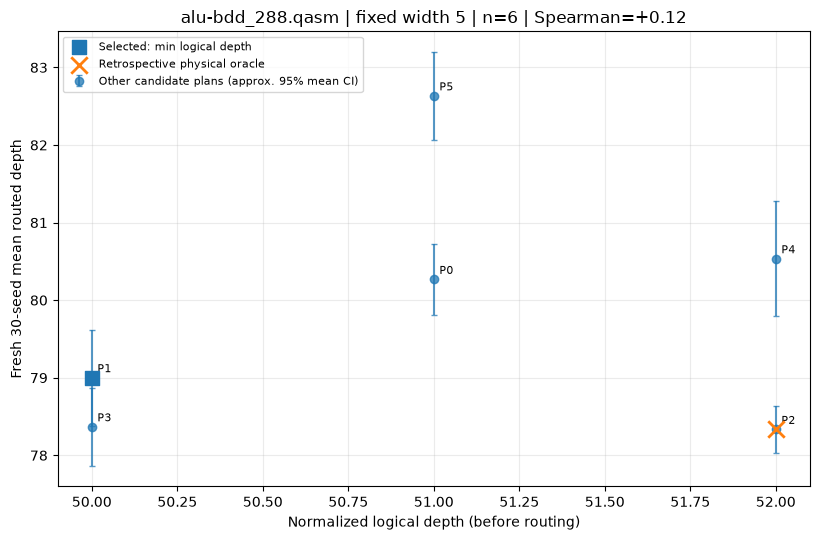

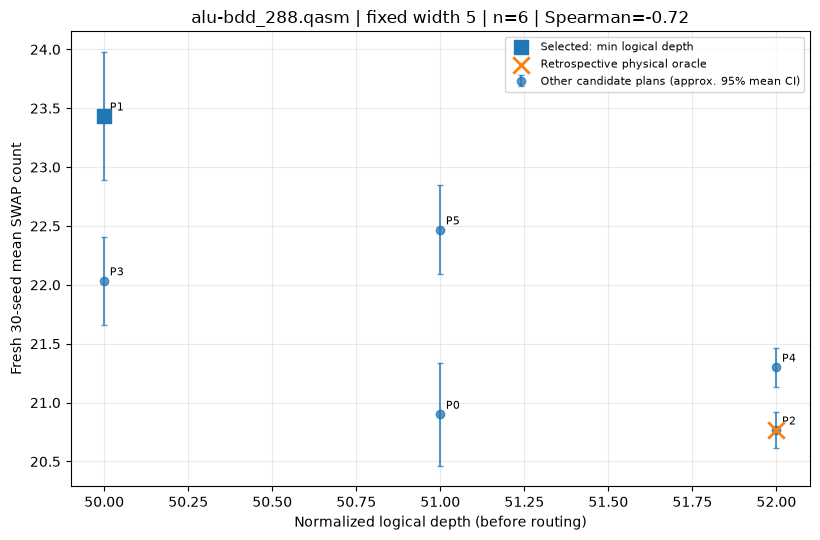

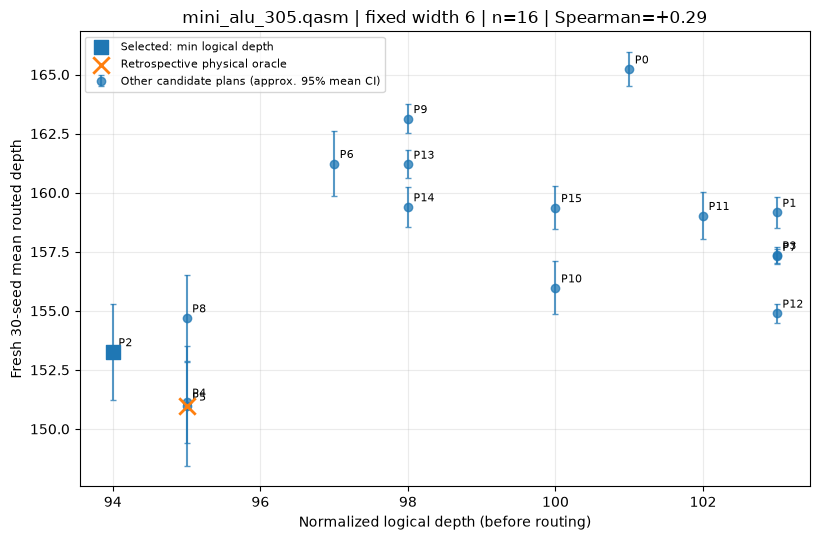

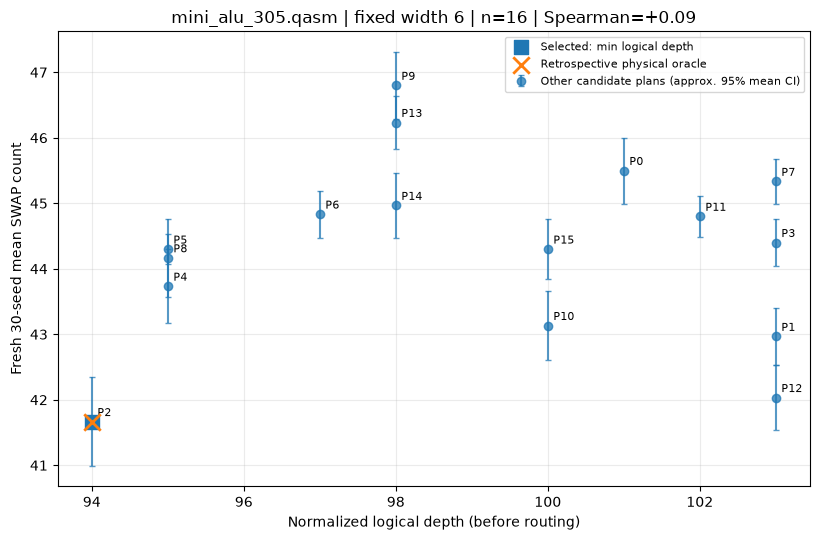

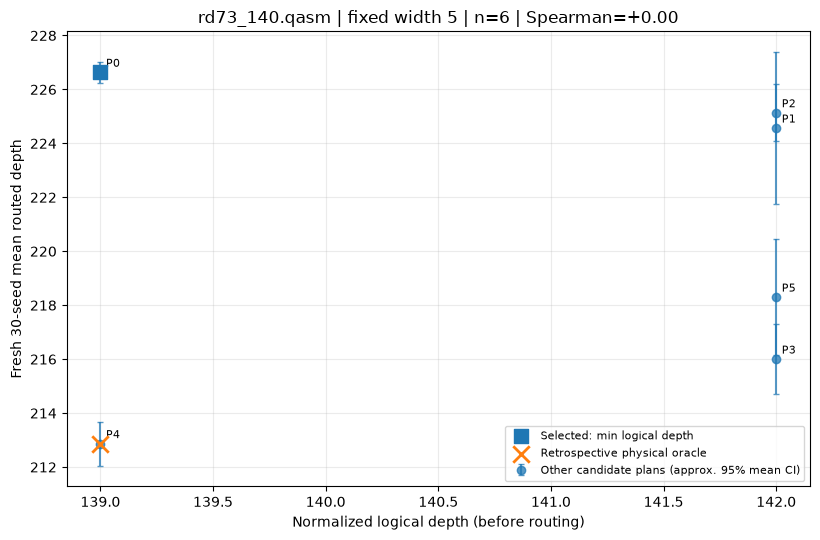

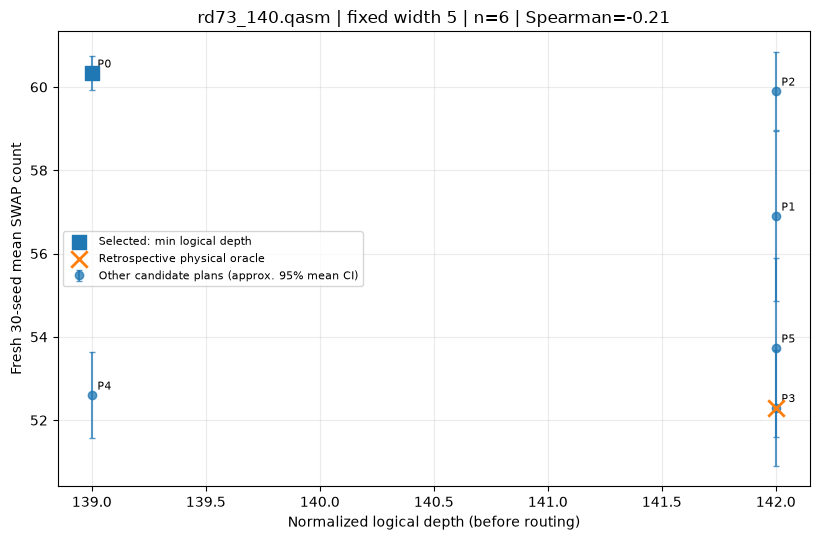

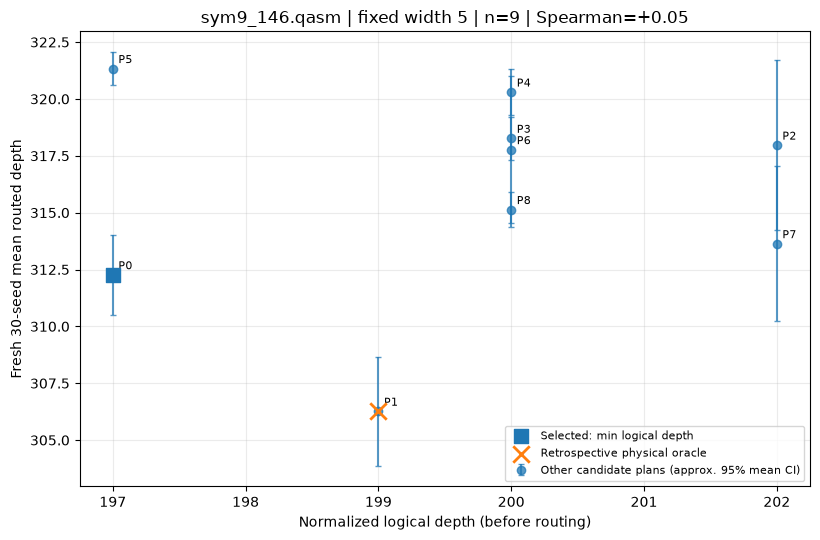

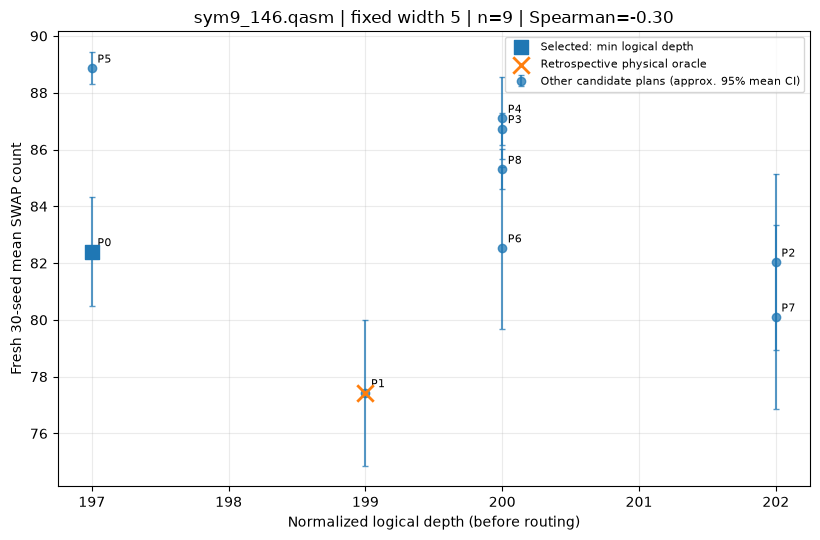

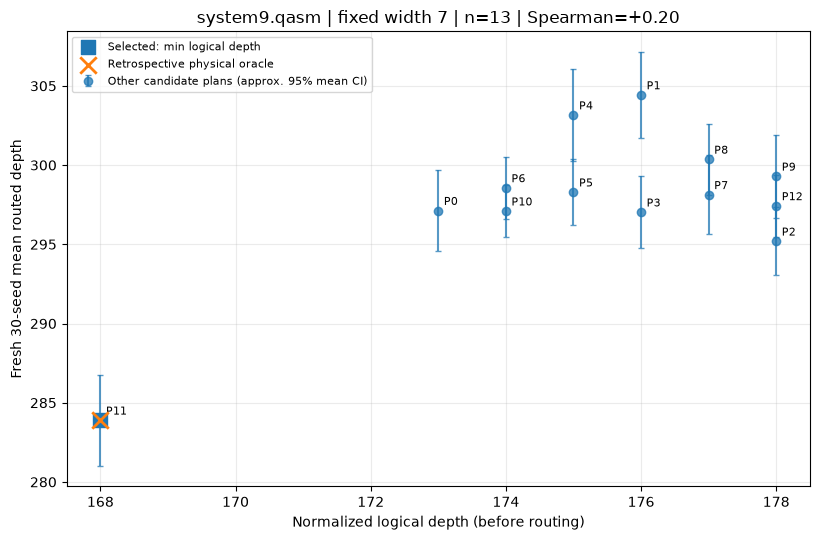

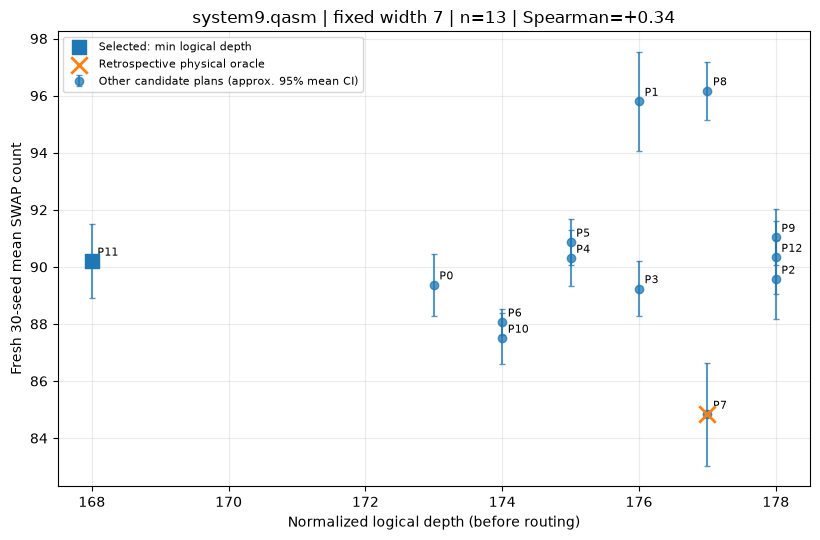

Saved 10 scatter figures to C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment4_results\figures


In [8]:
figure_paths = []
for circ, sub in ledger.groupby("circuit", sort=True):
    short = Path(circ).stem
    for target in ["routed_depth", "swaps"]:
        col = "fresh_mean_" + target
        std_col = "fresh_std_" + target
        selected = selection.loc[(selection.circuit == circ) & (selection.target == target)].iloc[0]
        min_depth_chosen = sub.loc[sub.plan_id.eq(selected.selected_plan)].iloc[0]
        oracle = sub.loc[sub.plan_id.eq(selected.oracle_plan)].iloc[0]

        fig, ax = plt.subplots(figsize=(8.3, 5.5))
        ax.errorbar(sub.normalized_logical_depth, sub[col],
                    yerr=1.96 * sub[std_col] / np.sqrt(sub.num_fresh_routing_trials),
                    fmt="o", capsize=2, alpha=0.75, label="Other candidate plans (approx. 95% mean CI)")
        ax.scatter([min_depth_chosen.normalized_logical_depth], [min_depth_chosen[col]],
                   marker="s", s=110, label="Selected: min logical depth", zorder=5)
        ax.scatter([oracle.normalized_logical_depth], [oracle[col]],
                   marker="x", s=140, linewidths=2, label="Retrospective physical oracle", zorder=6)
        for _, row in sub.iterrows():
            ax.annotate(str(row.plan_id), (row.normalized_logical_depth, row[col]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)
        rho = correlations.loc[(correlations.circuit == circ) & (correlations.target == target),
                               "fresh30_spearman"].iloc[0]
        ax.set_title(f"{circ} | fixed width {sub.width.iloc[0]} | n={len(sub)} | Spearman={rho:+.2f}")
        ax.set_xlabel("Normalized logical depth (before routing)")
        ax.set_ylabel("Fresh 30-seed mean " + ("routed depth" if target == "routed_depth" else "SWAP count"))
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
        fig.tight_layout()
        path = FIG_DIR / f"{short}_logical_vs_fresh30_{target}.png"
        fig.savefig(path, dpi=220, bbox_inches="tight")
        figure_paths.append(path)
        plt.show()
        plt.close(fig)
print(f"Saved {len(figure_paths)} scatter figures to {FIG_DIR}")

## 8 — Summary view: how much does the depth-only selection lose?
Regret = `(cost of selected min-depth plan − minimum cost among candidate plans) / minimum cost among candidate plans`. A value of 0% means the depth-only choice matches the retrospective oracle on these candidates. This does not guarantee anything on new circuits.

Regret (%) vs best available physical candidate:


target,routed_depth,swaps
circuit,,
alu-bdd_288.qasm,0.85,12.84
mini_alu_305.qasm,1.52,0.00
rd73_140.qasm,6.47,15.36
sym9_146.qasm,1.96,6.41
system9.qasm,0.00,6.33


Improvement (%) vs uniform random plan expectation (negative = depth selector is worse):


target,routed_depth,swaps
circuit,,
alu-bdd_288.qasm,1.07,-7.41
mini_alu_305.qasm,2.82,5.99
rd73_140.qasm,-2.74,-7.81
sym9_146.qasm,1.14,1.45
system9.qasm,4.63,0.06


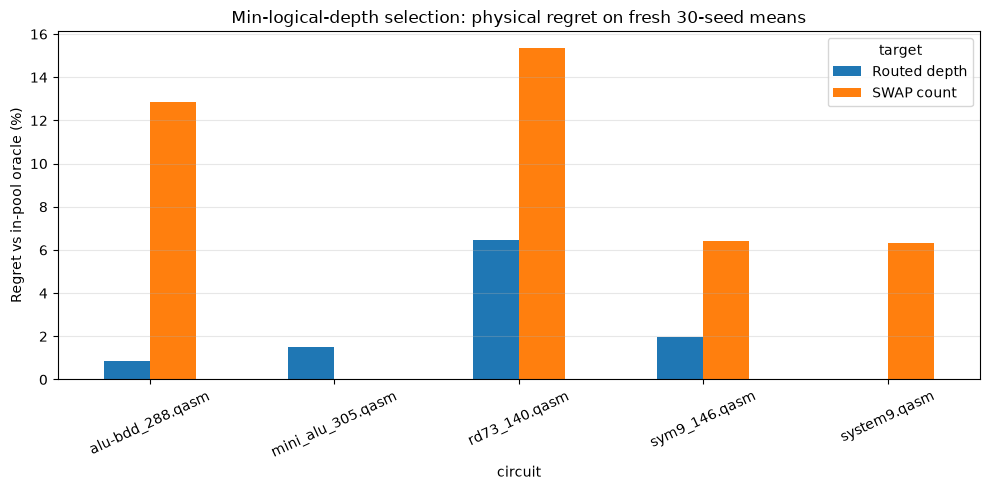

In [9]:
wide_regret = selection.pivot(index="circuit", columns="target", values="regret_vs_oracle_pct")
wide_random = selection.pivot(index="circuit", columns="target", values="improvement_vs_random_expected_pct")
print("Regret (%) vs best available physical candidate:")
display(wide_regret.round(2))
print("Improvement (%) vs uniform random plan expectation (negative = depth selector is worse):")
display(wide_random.round(2))

ax = wide_regret.rename(columns={"routed_depth": "Routed depth", "swaps": "SWAP count"}).plot(
    kind="bar", figsize=(10, 5), rot=25)
ax.set_ylabel("Regret vs in-pool oracle (%)")
ax.set_title("Min-logical-depth selection: physical regret on fresh 30-seed means")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
bar_path = FIG_DIR / "experiment4_min_depth_selection_regret.png"
plt.savefig(bar_path, dpi=220, bbox_inches="tight")
plt.show()
plt.close()
figure_paths.append(bar_path)

## 9 — Save results + provenance
This cell writes **only** inside `experiment4_results/`. Re-running it overwrites Experiment 4 outputs, never Experiment 1/2/3 files.

In [10]:
outputs = {
    "experiment4_plan_ledger.csv": ledger,
    "experiment4_correlations_by_circuit.csv": correlations,
    "experiment4_depth_selected_vs_oracle.csv": selection,
    "experiment4_pairwise_inversions.csv": pairwise,
    "experiment4_pairwise_summary.csv": pairwise_summary,
    "experiment4_top_counterexamples.csv": counterexamples,
    "experiment4_bootstrap_summary.csv": bootstrap_summary,
    "experiment4_bootstrap_draws.csv": bootstrap_draws,
}
for name, df in outputs.items():
    path = OUT_DIR / name
    df.to_csv(path, index=False)
    print(f"Saved {name} | rows={len(df)}")

provenance = {
    "experiment": "Experiment 4 — Logical vs. Physical Depth Analysis",
    "input_paths_relative_to_project_root": required_relative_paths,
    "input_sha256": {
        rel: hashlib.sha256((ROOT / rel).read_bytes()).hexdigest()
        for rel in required_relative_paths
    },
    "num_circuits": int(ledger.circuit.nunique()),
    "num_unique_plans": len(ledger),
    "n_old_routing_seeds": len(EXPECTED_OLD_SEEDS),
    "n_fresh_routing_seeds": len(EXPECTED_FRESH_SEEDS),
    "fresh_routing_seeds": sorted(EXPECTED_FRESH_SEEDS),
    "logical_depth_field": "normalized_logical_depth",
    "physical_targets": ["fresh_mean_routed_depth", "fresh_mean_swaps"],
    "depth_min_tie_breaker": "gidnet_seed ascending, plan_id ascending; no physical outcome used",
    "bootstrap": {
        "repetitions": BOOTSTRAP_REPS,
        "rng_seed": BOOTSTRAP_RANDOM_SEED,
        "unit_resampled": "joint routing-seed indices within each circuit; plans not resampled",
        "limitation": "seed sensitivity only; no cross-circuit generalization",
    },
    "python_version": sys.version,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scipy_version": __import__("scipy").__version__,
    "matplotlib_version": __import__("matplotlib").__version__,
}
with (OUT_DIR / "experiment4_provenance.json").open("w", encoding="utf-8") as f:
    json.dump(provenance, f, indent=2, ensure_ascii=False)
print("Saved experiment4_provenance.json")
print("\nFigures:", len(figure_paths))

Saved experiment4_plan_ledger.csv | rows=50
Saved experiment4_correlations_by_circuit.csv | rows=10
Saved experiment4_depth_selected_vs_oracle.csv | rows=10
Saved experiment4_pairwise_inversions.csv | rows=452
Saved experiment4_pairwise_summary.csv | rows=10
Saved experiment4_top_counterexamples.csv | rows=30
Saved experiment4_bootstrap_summary.csv | rows=10
Saved experiment4_bootstrap_draws.csv | rows=5000
Saved experiment4_provenance.json

Figures: 11


## 10 — How to interpret the results

1. **Check per-circuit correlation signs and magnitude.** Positive logical-vs-routed-depth Spearman means deeper logical plans *tend* to have greater routed depth; the relationship can be weak, negative, or circuit-dependent. Do not infer cause from association.
2. **Check depth-only choice rank and regret.** A useful depth heuristic should regularly select plans with good fresh routed depth, not merely have a positive correlation.
3. **Look at ties.** When multiple plans achieve minimum logical depth, a physical-aware tie-breaker could be valuable; report its cost fairly (it is not a pure depth-only selector).
4. **Inspect physical counterexamples.** They are direct evidence that minimizing logical depth is *not identical* to minimizing routed depth.
5. **Check seed-bootstrap sensitivity.** Narrow intervals suggest routing randomness does not change the observed relation much for these plans. This is **not** evidence of generalization to untested circuits.
6. **Decide next experiment:** If depth is strongly informative, develop and compare a fixed-width depth-aware search under **equal total runtime** against GidNET restart. If depth is weak but physical features are informative, use Experiment 5 to benchmark cheap selectors, with training/validation separated at the **circuit level**. If neither is strong, revisit physically relevant features or feasible neighborhoods.

**No final research-novelty claim or algorithmic improvement should be made from this notebook alone.**